In [8]:
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_datasets as tfds


In [3]:
import numpy as np
import matplotlib.pylab as plt

def format_image(image, label):
    image = tf.image.resize(image, (224,224)) /255.0
    return image, label

#carregar dados
(raw_train, raw_validation, raw_test), metadata = tfds.load(
    'rock_paper_scissors', 
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    with_info=True, 
    as_supervised=True,
)

num_examples = metadata.splits['train'].num_examples
num_classes = metadata.features['label'].num_classes #nesse caso 3 , pedra papel e tesoura
print(num_examples)
print(num_classes)
BATCH_SIZE = 32
train_batches = raw_train.shuffle(num_examples//4).map(format_image).batch(BATCH_SIZE).prefetch(1)
validation_batches = raw_validation.map(format_image).batch(BATCH_SIZE).prefetch(1)
test_batches = raw_test.map(format_image).batch(BATCH_SIZE).prefetch(1)

for image_batch, label_batch in train_batches.take(1):
    pass
image_batch.shape


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling C:\Users\iango\tensorflow_datasets\rock_paper_scissors\incomplete.C0BKR9_3.0.0\rock_paper_scissors-t…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling C:\Users\iango\tensorflow_datasets\rock_paper_scissors\incomplete.C0BKR9_3.0.0\rock_paper_scissors-t…

Dataset rock_paper_scissors downloaded and prepared to C:\Users\iango\tensorflow_datasets\rock_paper_scissors\3.0.0. Subsequent calls will reuse this data.
2520
3


TensorShape([32, 224, 224, 3])

In [10]:
#configuracao do modelo pre-treinado
module_handle = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"

#tamanho da imagem
IMAGE_SIZE = (224, 224)

#tamannho do vetor de recurso produzido por MobileNet V2. Representação numérica da imagem
FV_SIZE = 1280
num_classes = 3 #pedra papel tesoura

#carrega o modulo do tf hub, carregar o modelo pré-treinado feature_extrator pega uma img e retorna um vetor de recursos
feature_extractor = hub.load(module_handle)

#definir o modelo keras usando a api funcional
#definir entrada do model. As img tem dimensão 224x224x3 onde 3 são canais de cor RGB
entradas = tf.keras.Input(shape=IMAGE_SIZE + (3,))

#criar uma camada do lambda que aplique a função feature_extractor às entradas
#o uso do lambda é util para evitar erros ao integrar um modelo TF Hub em um modelo keras
feature_vector = tf.keras.layers.Lambda(lambda x: feature_extractor(x), output_shape=(FV_SIZE,), trainable=False)(entradas)

#adicionar uma camada densa final com neuronios num_classes e ativação softmax, para obter uma distribuição de probabilidade nas  classes

dense_output = tf.keras.layers.Dense(num_classes, activation = 'softmax')(feature_vector)

#definir o modelo completo especificando entradas e saídas
model = tf.keras.Model(inputs=entradas, outputs=dense_output)

#imprima um resumo da estrutura do modelo: camadas, dimensões de saída, número de parametros.
model.summary()
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,843 (15.01 KB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#como estamos realizando o aprendizado de transferencia para ajustar um modelo pre-treinado,
#em nosso conjunto de dados, so podemos usar 3
EPOCHS = 3
hist = model.fit(train_batches,
                 epochs=EPOCHS,
                 validation_data=validation_batches)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 136ms/step - accuracy: 0.8919 - loss: 0.3617 - val_accuracy: 0.9841 - val_loss: 0.1095
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.9950 - loss: 0.0730 - val_accuracy: 0.9960 - val_loss: 0.0563
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - accuracy: 0.9990 - loss: 0.0395 - val_accuracy: 1.0000 - val_loss: 0.0346


In [12]:
ROCK_PAPER_SCISSORS_MODEL = 'exp_saved_model' #onde vamos salvar o modelo
model.export(ROCK_PAPER_SCISSORS_MODEL)
#calculo da ocupação de memoria

import os
def get_directory_size(ROCK_PAPER_SCISSORS_MODEL):
    total = 0
    for dirpath, dirnames, filenames in os.walk(ROCK_PAPER_SCISSORS_MODEL):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            total += os.path.getsize(fp)
    return total / (1024 * 1024)  # em MB

file_size_saved_model = get_directory_size(ROCK_PAPER_SCISSORS_MODEL)
print(f'Tamanho do modelo salvo: {file_size_saved_model:.2f} MB')

INFO:tensorflow:Assets written to: exp_saved_model\assets


INFO:tensorflow:Assets written to: exp_saved_model\assets


Saved artifact at 'exp_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2599120348816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120170512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599111883472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120229712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120240080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120227600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120160912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120170704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120167632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120340560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2599120234704: TensorSpec(shape=(

In [14]:
# fase de redução
import pathlib

conversor = tf.lite.TFLiteConverter.from_saved_model(ROCK_PAPER_SCISSORS_MODEL)
conversor.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_data_gen():
    for input_value, _ in train_batches.take(100):
        yield [input_value]

conversor.representative_dataset = representative_data_gen
conversor.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]

tflite_model = conversor.convert()

tflite_model_dir = pathlib.Path(r"C:\tmp")
tflite_model_dir.mkdir(parents=True, exist_ok=True)

tflite_model_file = tflite_model_dir / "model3.tflite"
tflite_model_file.write_bytes(tflite_model)


2705944

In [23]:
# 7) Teste com validação do modelo examinado (model1, model2 ou model3)
# @title Execute esta célula sempre que quiser testar a acurácia modelo
from tqdm import tqdm
tflite_model_file = r"C:\tmp\model3.tflite"
interpreter = tf.lite.Interpreter(model_path=str(tflite_model_file))
interpreter.allocate_tensors()

input_index = interpreter.get_input_details()[0]['index']
output_index = interpreter.get_output_details()[0]['index']
predictions = []
test_labels, test_imgs = [], []

for img, label in tqdm(test_batches.take(100)):
    img = img[0:1]        # <- pega só 1 imagem (batch=1)
    label = label[0]      # <- label correspondente

    interpreter.set_tensor(input_index, img)
    interpreter.invoke()
    predictions.append(interpreter.get_tensor(output_index))
    test_labels.append(label.numpy())  # <- agora label é escalar
    test_imgs.append(img)

score = 0

for item in range(len(predictions)):
    pred = np.argmax(predictions[item])  
    label = test_labels[item]
    if pred == label:
        score += 1

print("De 100 previsões que recebi " + str(score) + " correto.")


100%|██████████| 8/8 [00:00<00:00, 158.27it/s]

De 100 previsões que recebi 8 correto.


In [31]:
#funcao de utilidade para representação grafica
class_names = ['rock', 'paper', 'scissors']
def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    #extrair os dados relacionado ao indice i
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    img = np.squeeze(img)
    plt.imshow(img)
    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'green'
    else:
        color = 'red'
    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                  100*np.max(predictions_array),
                                  class_names[true_label]),
                                  color=color)


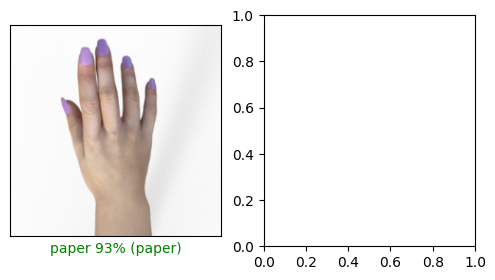

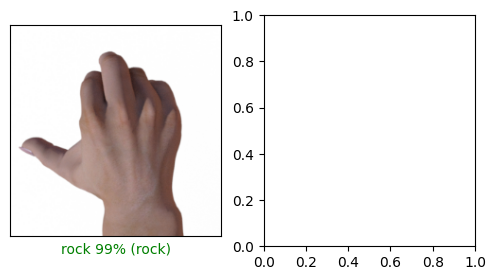

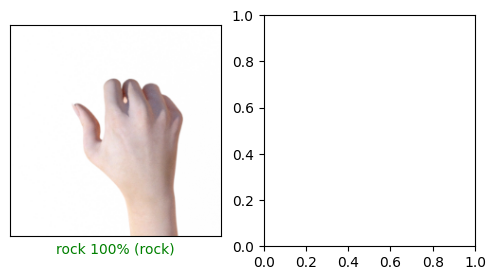

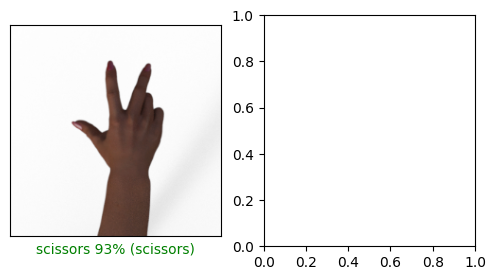

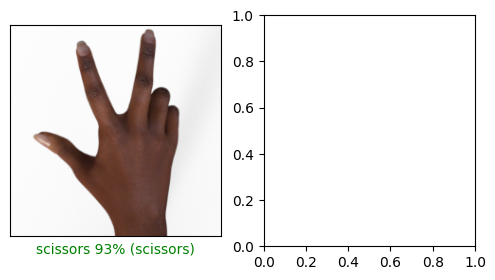

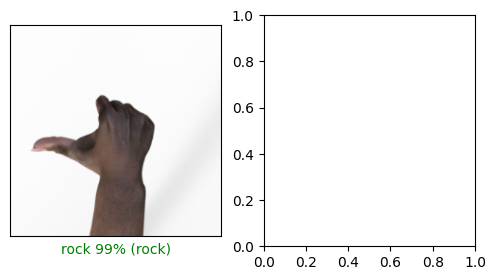

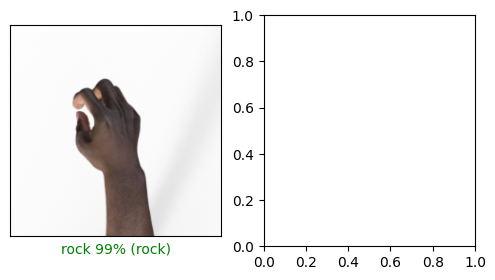

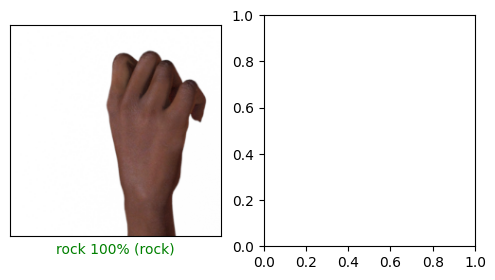

In [32]:
#exibir saidas toda vez {run:"auto"}
max_index = len(predictions)
for index in range(0, max_index):
    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plot_image(index, predictions, test_labels, test_imgs)
    plt.subplot(1,2,2)
    plt.show()